In [1]:
import os, time
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             accuracy_score, f1_score, recall_score)

FIG = os.path.join(os.getcwd(), "..", "reports", "figures")
os.makedirs(FIG, exist_ok=True)

d = joblib.load(os.path.join(os.getcwd(), "..", "data", "processed", "preprocessed.joblib"))
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
class_names = d["label_classes"]

stack = joblib.load(os.path.join(os.getcwd(), "..", "models", "stacking_model.joblib"))
print("Loaded. Test set:", X_test.shape)

def per_class_fpr(cm):
    FP = cm.sum(0) - np.diag(cm); TP = np.diag(cm)
    FN = cm.sum(1) - np.diag(cm); TN = cm.sum() - (FP + FN + TP)
    return FP / (FP + TN)

Loaded. Test set: (565566, 64)


In [5]:
proba = stack.predict_proba(X_test)
pred  = proba.argmax(1)

acc   = accuracy_score(y_test, pred)
mf1   = f1_score(y_test, pred, average="macro")
wf1   = f1_score(y_test, pred, average="weighted")
auc   = roc_auc_score(y_test, proba, multi_class="ovr", average="macro")

print(f"Accuracy      : {acc:.4f}")
print(f"Macro-F1      : {mf1:.4f}")
print(f"Weighted-F1   : {wf1:.4f}")
print(f"ROC-AUC (ovr) : {auc:.4f}\n")

# per-class table (precision / recall / F1 + FPR), saved to CSV
rep = classification_report(y_test, pred, target_names=class_names,
                            digits=4, zero_division=0, output_dict=True)
cm = confusion_matrix(y_test, pred)
fpr = per_class_fpr(cm)

per_class = pd.DataFrame({
    "precision": [rep[c]["precision"] for c in class_names],
    "recall":    [rep[c]["recall"]    for c in class_names],
    "f1":        [rep[c]["f1-score"]  for c in class_names],
    "FPR":       fpr,
    "support":   [int(rep[c]["support"]) for c in class_names],
}, index=class_names).round(4)
per_class.to_csv(os.path.join(FIG, "..", "stacking_per_class.csv"))
print(per_class)
print(f"\nMacro FPR: {fpr.mean():.5f}")

Accuracy      : 0.9990
Macro-F1      : 0.9755
Weighted-F1   : 0.9990
ROC-AUC (ovr) : 0.9998

                  precision  recall      f1     FPR  support
BENIGN               0.9997  0.9991  0.9994  0.0012   454264
Bot                  0.7517  0.8440  0.7952  0.0002      391
DDoS                 1.0000  0.9997  0.9998  0.0000    25605
DoS GoldenEye        0.9976  0.9947  0.9961  0.0000     2059
DoS Hulk             0.9985  0.9991  0.9988  0.0001    46025
DoS Slowhttptest     0.9503  0.9909  0.9702  0.0001     1100
DoS slowloris        0.9966  0.9983  0.9974  0.0000     1159
FTP-Patator          0.9994  0.9981  0.9987  0.0000     1587
PortScan             0.9939  0.9995  0.9967  0.0004    31761
SSH-Patator          1.0000  1.0000  1.0000  0.0000     1179
Web Attack           0.9815  0.9748  0.9781  0.0000      436

Macro FPR: 0.00018


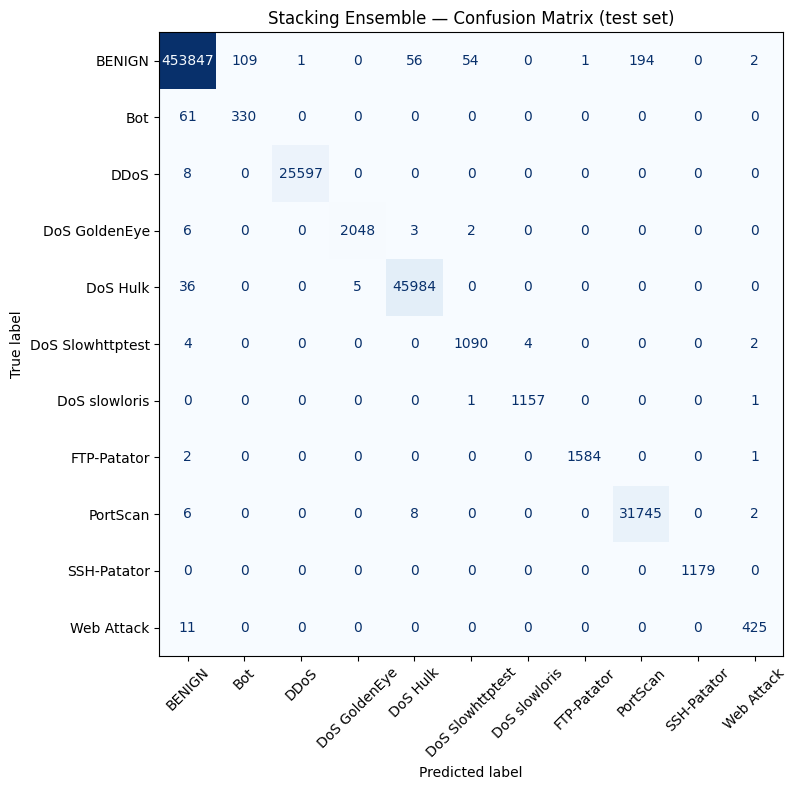

Saved confusion_matrix.png


In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("Stacking Ensemble — Confusion Matrix (test set)")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "confusion_matrix.png"), dpi=150)
plt.show()
print("Saved confusion_matrix.png")

In [4]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

bot = class_names.index("Bot")

def headline(name, model):
    p = model.predict(X_test)
    return {"model": name,
            "accuracy": round(accuracy_score(y_test, p), 4),
            "macro_F1": round(f1_score(y_test, p, average="macro"), 4),
            "weighted_F1": round(f1_score(y_test, p, average="weighted"), 4),
            "Bot_recall": round(recall_score(y_test, p, labels=[bot], average="macro"), 4)}

print("Training RF baseline..."); t=time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=30, min_samples_leaf=2,
                            n_jobs=4, random_state=42).fit(X_train, y_train)
print(f"  done in {time.time()-t:.0f}s")
xgb = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.3, tree_method="hist",
                    device="cuda", eval_metric="mlogloss", random_state=42).fit(X_train, y_train)

comparison = pd.DataFrame([
    headline("RandomForest (baseline)", rf),
    headline("XGBoost (baseline)", xgb),
    {"model": "Stacking + within-fold SMOTE", "accuracy": round(acc,4),
     "macro_F1": round(mf1,4), "weighted_F1": round(wf1,4),
     "Bot_recall": round(recall_score(y_test, pred, labels=[bot], average="macro"),4)},
]).set_index("model")
comparison.to_csv(os.path.join(FIG, "..", "model_comparison.csv"))
print("\n", comparison)

Training RF baseline...
  done in 377s

                               accuracy  macro_F1  weighted_F1  Bot_recall
model                                                                    
RandomForest (baseline)         0.9979    0.9563       0.9979      0.4987
XGBoost (baseline)              0.9987    0.9690       0.9987      0.7519
Stacking + within-fold SMOTE    0.9990    0.9755       0.9990      0.8440


In [7]:
import shap
xgb_in = stack.named_estimators_["xgb"].named_steps["xgb"]; xgb_in.set_params(device="cpu")
explainer = shap.TreeExplainer(xgb_in)
one = X_test[:1]

t=time.time()
for _ in range(100): stack.predict(one)
infer_ms = (time.time()-t)/100*1000
t=time.time()
for _ in range(100): explainer(one)
shap_ms = (time.time()-t)/100*1000
print(f"Inference latency : {infer_ms:.2f} ms/flow")
print(f"SHAP overhead     : {shap_ms:.2f} ms/flow")

Inference latency : 32.52 ms/flow
SHAP overhead     : 7.00 ms/flow


In [2]:
import os, time
import numpy as np, joblib
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# --- self-contained: reload data so this works even after a kernel restart ---
d = joblib.load(os.path.join(os.getcwd(), "..", "data", "processed", "preprocessed.joblib"))
X_train, y_train = d["X_train"], d["y_train"]

CV_SUBSAMPLE   = 300_000     # stratified subsample for the stability estimate
CV_SMOTE_FLOOR = 15_000

Xc, _, yc, _ = train_test_split(X_train, y_train, train_size=CV_SUBSAMPLE,
                                stratify=y_train, random_state=42)

def smote_floor(y):
    c = Counter(y)
    return {k: CV_SMOTE_FLOOR for k, n in c.items() if n < CV_SMOTE_FLOOR}

def make_stack():
    rf = ImbPipeline([("smote", SMOTE(sampling_strategy=smote_floor, k_neighbors=5, random_state=42)),
                      ("rf", RandomForestClassifier(n_estimators=100, max_depth=30,
                                                    min_samples_leaf=2, n_jobs=2, random_state=42))])
    xgb = ImbPipeline([("smote", SMOTE(sampling_strategy=smote_floor, k_neighbors=5, random_state=42)),
                       ("xgb", XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.3,
                                             tree_method="hist", device="cuda",
                                             eval_metric="mlogloss", random_state=42))])
    return StackingClassifier(estimators=[("rf", rf), ("xgb", xgb)],
                              final_estimator=LogisticRegression(max_iter=1000),
                              stack_method="predict_proba",
                              cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=1)

print(f"5-fold CV on {CV_SUBSAMPLE:,} flows (SMOTE floor {CV_SMOTE_FLOOR:,}, n_jobs=2) — this will take a while...")
t = time.time()
cvres = cross_validate(make_stack(), Xc, yc,
                       cv=StratifiedKFold(5, shuffle=True, random_state=42),
                       scoring=["accuracy", "f1_macro", "f1_weighted"], n_jobs=1)
print(f"done in {(time.time()-t)/60:.1f} min\n")
for m in ["accuracy", "f1_macro", "f1_weighted"]:
    s = cvres["test_" + m]
    print(f"{m:12s}: {s.mean():.4f} ± {s.std():.4f}")

5-fold CV on 300,000 flows (SMOTE floor 15,000, n_jobs=2) — this will take a while...


C:\Users\OMEN\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\xgboost\core.py:569: UserWarning: [10:17:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


done in 21.4 min

accuracy    : 0.9988 ± 0.0001
f1_macro    : 0.9751 ± 0.0029
f1_weighted : 0.9988 ± 0.0001
